# 01. Первинний аналіз Telco Customer Churn

Мета: зрозуміти структуру та якість даних, розподіл відтоку й потенційні особливості ознак. Це описовий аналіз, а не навчання чи оцінювання моделі. Оригінальний CSV не змінюється.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Завантаження даних

Завантажте CSV згідно з README, якщо він ще відсутній. Ноутбук підтримує запуск із кореня проєкту або каталогу `notebooks`.

In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
data_path = project_root / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Не знайдено {data_path}. Інструкції із завантаження є в README.md.")

df = pd.read_csv(data_path)
print(f"Рядків: {df.shape[0]}, стовпців: {df.shape[1]}")
display(df.head())

Рядків: 7043, стовпців: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Структура та якість даних

Перевіряємо типи, пропущені значення, повні дублікати та повтори ідентифікаторів. `customerID` — ідентифікатор, а не предиктор.

In [3]:
df.info()
display(pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum(), "унікальних": df.nunique(dropna=True)}))
print(f"Повні дублікати рядків: {df.duplicated().sum()}")
print(f"Повторні customerID: {df['customerID'].duplicated().sum()}")
display(df.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,тип,пропуски,унікальних
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Повні дублікати рядків: 0
Повторні customerID: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Перевірка `TotalCharges`

Поле може містити порожні рядки. Діагностуємо порожні й інші нечислові значення окремо; перетворена серія існує лише в пам'яті і не змінює сирий CSV.

In [4]:
total_text = df["TotalCharges"].astype("string").str.strip()
total_numeric = pd.to_numeric(total_text, errors="coerce")
empty_total = total_text.isna() | total_text.eq("").fillna(False)
invalid_total = total_numeric.isna() & ~empty_total
print(f"Порожні або пропущені TotalCharges: {empty_total.sum()}")
print(f"Інші нечислові TotalCharges: {invalid_total.sum()}")
display(df.loc[empty_total | invalid_total, ["customerID", "tenure", "TotalCharges"]])

Порожні або пропущені TotalCharges: 11
Інші нечислові TotalCharges: 0


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


## Цільова змінна

Порівняйте кількість і частку класів. Дисбаланс може зробити accuracy недостатньою метрикою.

,кількість,частка
Churn,,
No,5174,0.73463
Yes,1869,0.26537


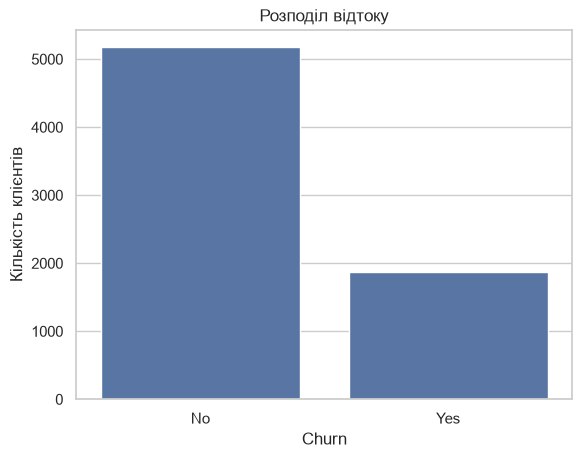

In [5]:
churn_counts = df["Churn"].value_counts(dropna=False)
display(pd.DataFrame({"кількість": churn_counts, "частка": churn_counts / len(df)}))
ax = sns.countplot(data=df, x="Churn", order=["No", "Yes"])
ax.set(title="Розподіл відтоку", xlabel="Churn", ylabel="Кількість клієнтів")
plt.show()

## Числові та категоріальні ознаки

Ці графіки показують асоціації у повному наборі, а не причинні зв'язки. Не використовуйте їх як незалежну тестову оцінку.

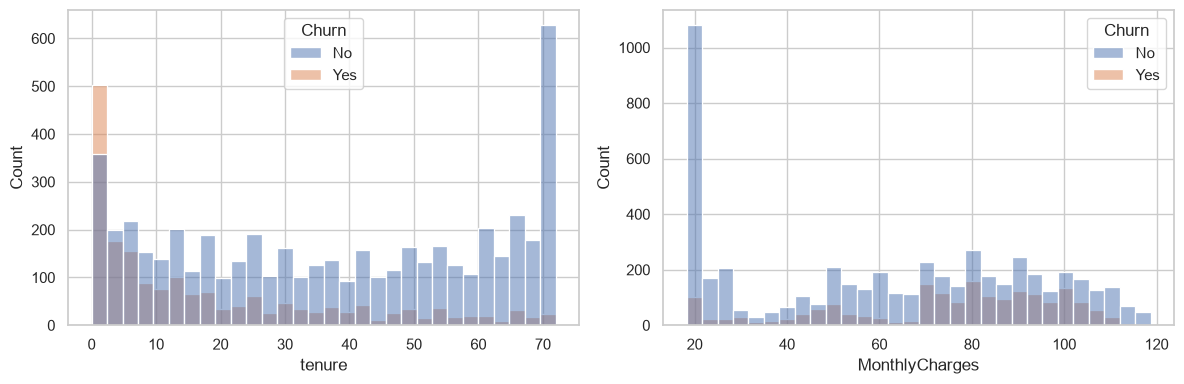

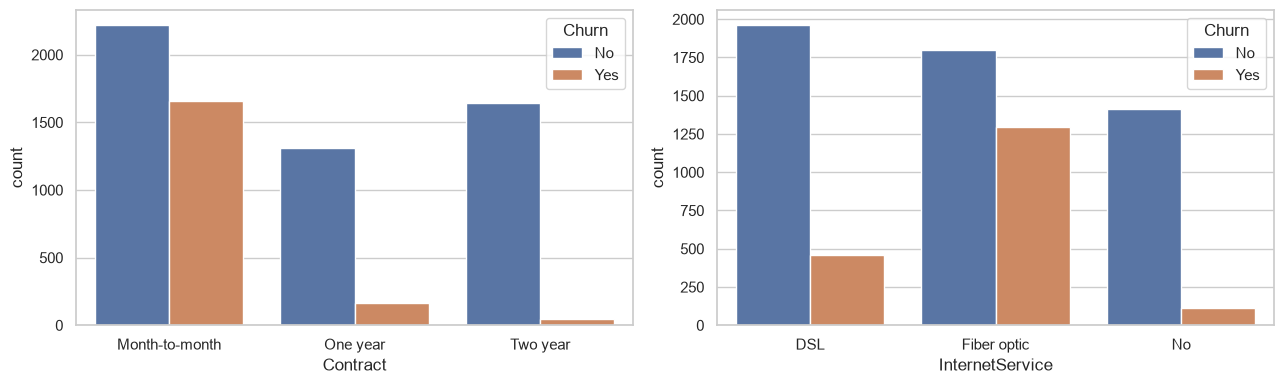

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", multiple="layer", bins=30, ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", multiple="layer", bins=30, ax=axes[1])
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
sns.countplot(data=df, x="InternetService", hue="Churn", ax=axes[1])
fig.tight_layout()
plt.show()

## Висновки та наступні кроки

Для зафіксованого в README CSV початкові спостереження такі:

- 7 043 рядки, 21 стовпець; повних дублікатів і повторних `customerID` не виявлено.
- `Churn = Yes`: 1 869 (26,54%); `No`: 5 174 (73,46%). Класи незбалансовані, тому однієї accuracy недостатньо.
- `TotalCharges` містить 11 порожніх значень і жодного іншого нечислового значення; у всіх 11 записів `tenure = 0`. Це спостереження, а не підстава автоматично замінювати значення нулями.
- `customerID` є ідентифікатором; його не слід використовувати як ознаку моделі.

Це опис усього набору, а не оцінка моделі. Перед вибором ознак та розробкою моделі відокремте тестову вибірку; план експериментів наведено в README.